# <font color='yellow'>Viés e Variância </font>

**<font color='yellow'>Viés</font>**

O viés de um modelo de ML refere-se ao <font color='yellow'>erro de ajuste que este modelo gera ao tentar aproximar um problema real</font>. O viés está intimamente relacionado à capacidade do modelo em se ajustar à relação que ocorre na realidade.

- <font color='yellow'>Alto Viés</font>: Um modelo com alto viés tende a subajustar (<font color='yellow'>underfitting</font>) os dados. Isso significa que ele é muito simples para capturar os padrões nos dados, resultando em previsões que estão consistentemente erradas. Um exemplo comum seria o uso de um modelo linear para capturar uma relação não-linear;

- <font color='yellow'>Baixo Viés</font>: Indica que o modelo consegue capturar bem as complexidades dos dados, ajustando-se adequadamente aos mesmos.

**<font color='yellow'>Variância </font>**

O problema de variância está relacionado à <font color='yellow'>sensibilidade do modelo aos dados</font>. De forma mais simples, é possível descrever a variância como sendo a medida pela qual o valor predito mudaria, caso este modelo fosse treinado com dados diferentes.

- <font color='yellow'>Alta Variância</font>: Um modelo com alta variância tende a sobreajustar (<font color='yellow'>overfitting</font>) os dados. Ele se ajusta muito bem aos dados de treinamento, mas falha em prever novos dados corretamente, porque é muito sensível às variações nos dados de treinamento.

- <font color='yellow'>Baixa Variância</font>: Indica que o modelo é mais robusto em relação a mudanças nos dados de treinamento e pode generalizar melhor para dados novos.

Analisaremos o que acontece com um modelo à medida que variamos o ruído (noise) gerado pelo sinal (signal) gerador de dados e analisaremos os resultados.


In [1]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')


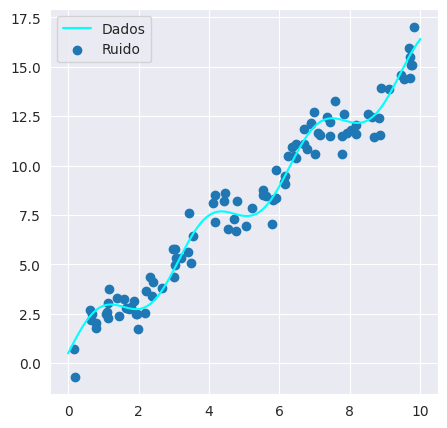

In [2]:
# Geração de dados sintéticos

def generate_data(x, noise_threshold=0.1):
    signal = np.sin(2 * x) + (1.5 * x) + 0.5
    noise = np.random.normal(0, 1, size=len(x)) * noise_threshold
    return signal + noise


x = np.random.uniform(0, 10, 100)
y = generate_data(x=x, noise_threshold=0.7)

plt.figure(figsize=(5, 5))

signal_x = np.linspace(0, 10, 100)
signal_y = generate_data(x=signal_x, noise_threshold=0.0)
plt.plot(signal_x, signal_y, color='cyan', label='Dados')

plt.scatter(x=x, y=y, label='Ruido')

plt.legend()
plt.show()


# <font color='yellow'>Alto viés e Baixa variância</font>

1. <font color='yellow'>Alto viés</font>: conforme o ruído gerado pelo sinal varia, a distância média entre o ajuste e o sinal é alta;
2. <font color='yellow'>Baixa variância</font>: conforme o ruído gerado pelo sinal varia, o ajuste não varia muito.

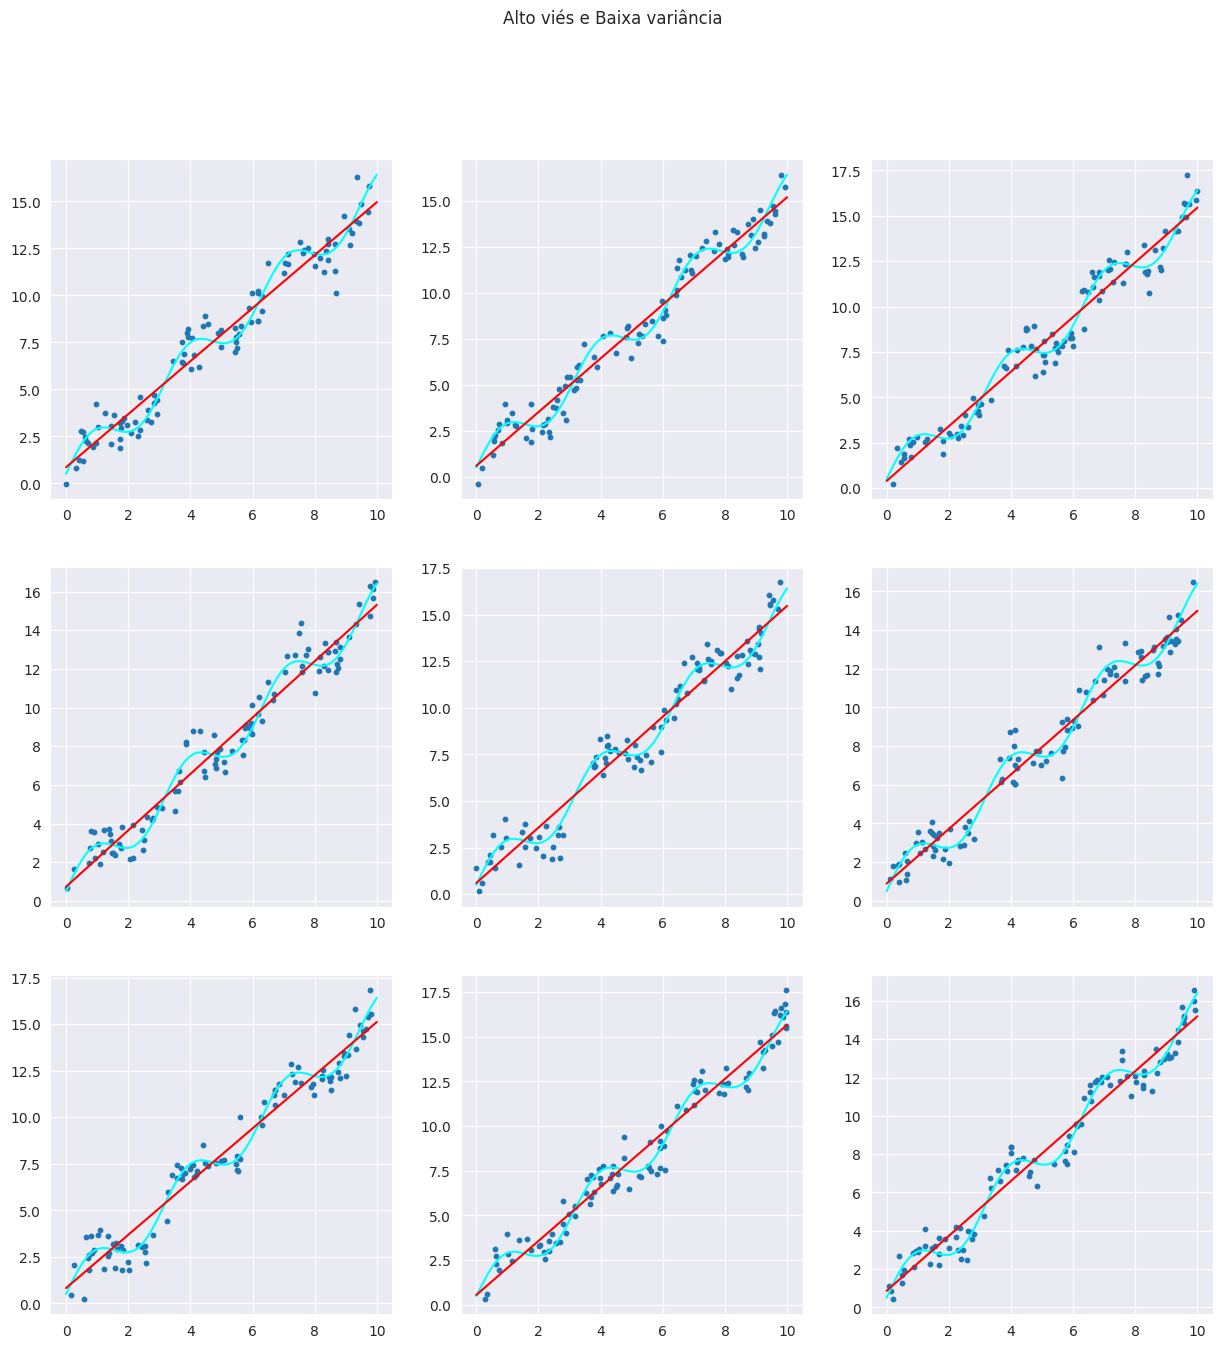

In [3]:
plt.figure(figsize=(15, 15))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    signal_x = np.linspace(0, 10, 100)
    signal_y = generate_data(x=signal_x, noise_threshold=0.0)
    plt.plot(signal_x, signal_y, color='cyan')

    x = np.random.uniform(0, 10, 100)
    y = generate_data(x=x, noise_threshold=0.7)
    plt.scatter(x=x, y=y, s=10)

    model = LinearRegression()
    model.fit(np.expand_dims(x, axis=1), y)

    fit_x = np.linspace(0, 10, 100)
    fit_y = (model.coef_ * fit_x) + model.intercept_
    plt.plot(fit_x, fit_y, color='red')

plt.suptitle('Alto viés e Baixa variância')
plt.show()


# <font color='yellow'>Alta Variância e Baixo Viés</font>

1. <font color='yellow'>Alta variância</font>: Conforme o ruído gerado pelo sinal varia, o ajuste varia substancialmente;
2. <font color='yellow'>Baixo viés</font>: Conforme o ruído gerado pelo sinal varia, a distância média entre o ajuste e o sinal é baixa.

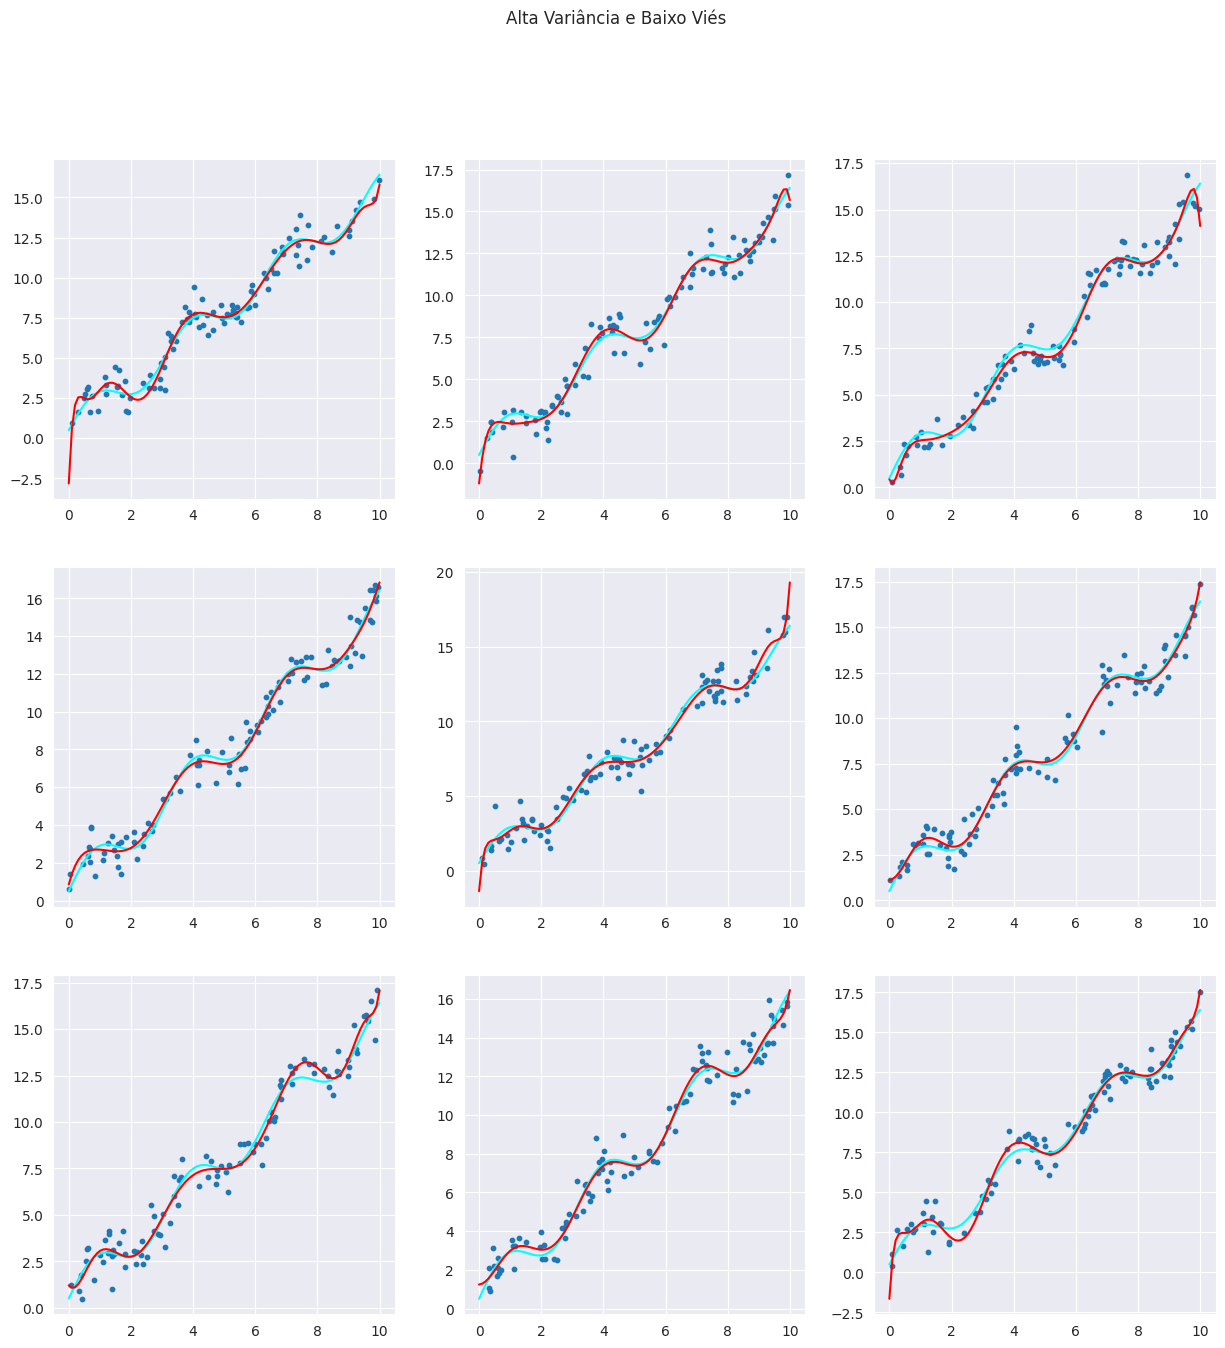

In [4]:
def generate_features(x, deg):
    return np.stack([x**i for i in range(1, deg + 1)]).T


deg = 13

plt.figure(figsize=(15, 15))

for i in range(9):
    plt.subplot(3, 3, i + 1)

    signal_x = np.linspace(0, 10, 100)
    signal_y = generate_data(x=signal_x, noise_threshold=0.0)
    plt.plot(signal_x, signal_y, color='cyan')

    x = np.random.uniform(0, 10, 100)
    y = generate_data(x=x, noise_threshold=0.7)
    plt.scatter(x=x, y=y, s=10)

    X = generate_features(x, deg=deg)
    model = LinearRegression()
    model.fit(X, y)

    fit_x = np.linspace(0, 10, 100)
    fit_X = generate_features(fit_x, deg=deg)
    fit_y = np.matmul(fit_X, model.coef_) + model.intercept_
    plt.plot(fit_x, fit_y, color='red')

plt.suptitle('Alta Variância e Baixo Viés')
plt.show()
